# 05b — Quick feature screen (Bogotá)

The full LOYO-cross-validated sequential feature selection (notebook 06) takes
60-90+ minutes per run, which is too slow for "did this new feature help at all?"
feedback while iterating on the candidate pool. This notebook is a **fast diagnostic**
(seconds, not an hour): fit a single flexible model (XGBoost) on a simple time-based
train/test split over ALL candidates, and look at test R² and feature importances.

This is not a substitute for notebook 06 — a single train/test split can overfit to
that particular split, and XGBoost importances aren't the same as genuinely
cross-validated, non-redundant predictive value. It's purely a cheap early-warning
signal: if a newly engineered feature (e.g. `lts`, `blh_morning_mean`) doesn't even
show up in the top ~20 importances here, it's very unlikely to survive the full SFS,
and we can iterate on the feature pool before paying for the expensive run.


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("/path/to/project")
sys.path.insert(0, str(PROJECT_ROOT / "Scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.metrics import r2_score

DATA_DIR = PROJECT_ROOT / "Data" / "processed" / "colombia" / "bogota"
FIG_DIR = PROJECT_ROOT / "Scripts" / "colombia" / "bogota" / "figures"

df = pd.read_parquet(DATA_DIR / "bogota_master_dataset.parquet")
df = df.dropna(subset=['pm25']).reset_index(drop=True)
df['year'] = df['date'].dt.year

EXCLUDE = {'date', 'pm25', 'year', 'season'}
CAUSAL_EXCLUDE = {c for c in df.columns if c == 'pm10' or c.startswith('pm10_lag')}
CAUSAL_EXCLUDE |= {c for c in df.columns if c == 'o3' or c.startswith('o3_lag')}
CAUSAL_EXCLUDE |= {c for c in df.columns if c == 'pm25_lag1'}  # autoregressive, tracked separately
EXCLUDE |= CAUSAL_EXCLUDE
CANDIDATES = [c for c in df.columns if c not in EXCLUDE]
print(f"{len(CANDIDATES)} candidates (PM10/O3/pm25_lag1 excluded, same as notebook 06)")


129 candidates (PM10/O3/pm25_lag1 excluded, same as notebook 06)


## Time-based train/test split

Train on 2014-2022, test on 2023-2025 (held-out *future* years, no leakage) -- a single
split, not cross-validated, purely for fast screening.


In [2]:
train = df[df['year'] <= 2022]
test = df[df['year'] >= 2023]
print(f"train: {len(train)} rows ({train['year'].min()}-{train['year'].max()})")
print(f"test:  {len(test)} rows ({test['year'].min()}-{test['year'].max()})")

Xtr, ytr = train[CANDIDATES], train['pm25']
Xte, yte = test[CANDIDATES], test['pm25']

model = XGBRegressor(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, random_state=0,
    missing=np.nan,  # XGBoost handles NaN natively -- no need to drop rows
)
model.fit(Xtr, ytr)
pred = model.predict(Xte)
print(f"Held-out test R2 (2023-2025): {r2_score(yte, pred):.3f}")


train: 3287 rows (2014-2022)
test:  1096 rows (2023-2025)
Held-out test R2 (2023-2025): 0.412


## Top 25 feature importances

wind_dir_sin                    0.091952
month_sin                       0.064254
precip_total_mm                 0.050818
doy_cos                         0.049314
wind_dir                        0.043461
radiation_mean                  0.022180
secondary_pm_proxy              0.021867
pressure_lag1                   0.021043
ventilation_min                 0.018861
hotspots_eastern_plains_lag3    0.017965
blh_min                         0.017817
doy_sin                         0.017571
month_cos                       0.016279
day_of_week                     0.015890
ventilation_min_lag1            0.015773
hotspots_cvb_lag3               0.014400
radiation_mean_lag1             0.014182
no2_lag3                        0.013729
hotspots_cvb_lag2               0.013696
pressure_lag3                   0.012381
pressure_lag2                   0.012225
pressure                        0.011388
lts_morning                     0.010905
temp_10m                        0.008910
no2             

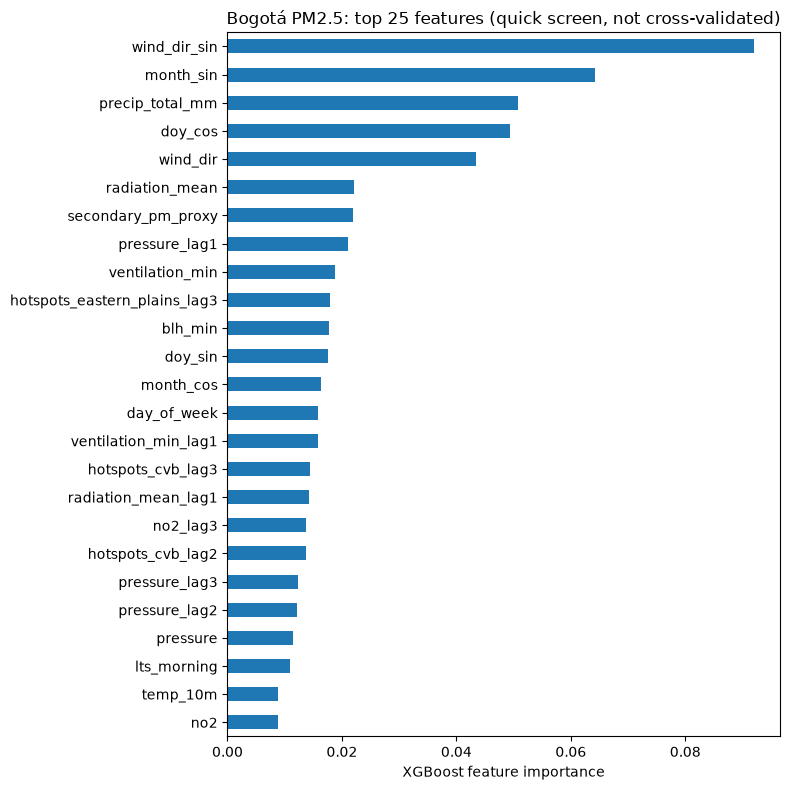

In [3]:
importances = pd.Series(model.feature_importances_, index=CANDIDATES).sort_values(ascending=False)
top25 = importances.head(25)
print(top25)

fig, ax = plt.subplots(figsize=(8, 8))
top25[::-1].plot.barh(ax=ax)
ax.set_xlabel('XGBoost feature importance')
ax.set_title('Bogotá PM2.5: top 25 features (quick screen, not cross-validated)')
fig.tight_layout()
fig.savefig(FIG_DIR / 'quick_screen_importances.png', dpi=150)
plt.show()


## Do the new v4 stagnation/stability features show up at all?


In [4]:
v4_features = [c for c in CANDIDATES if any(
    tag in c for tag in ['lts', 'blh_morning', 'ventilation_min', 'fog_stagnation', 'dry_stagnation', 'secondary_pm_proxy']
)]
v4_ranks = importances.rank(ascending=False)[v4_features].sort_values()
print(f"{len(v4_features)} v4 feature columns (incl. lags); ranks out of {len(CANDIDATES)}:")
print(v4_ranks)


28 v4 feature columns (incl. lags); ranks out of 129:
secondary_pm_proxy           7.0
ventilation_min              9.0
ventilation_min_lag1        15.0
lts_morning                 23.0
blh_morning_mean            26.0
secondary_pm_proxy_lag1     30.0
lts                         39.0
lts_lag1                    47.0
fog_stagnation_lag1         51.0
fog_stagnation              59.0
dry_stagnation_lag3         61.0
secondary_pm_proxy_lag3     65.0
blh_morning_mean_lag1       67.0
fog_stagnation_lag3         77.0
fog_stagnation_lag2         78.0
secondary_pm_proxy_lag2     79.0
dry_stagnation_lag2         81.0
ventilation_min_lag2        84.0
lts_morning_lag1            88.0
dry_stagnation              90.0
lts_lag2                    91.0
ventilation_min_lag3        94.0
lts_lag3                    97.0
lts_morning_lag3           105.0
lts_morning_lag2           108.0
dry_stagnation_lag1        111.0
blh_morning_mean_lag3      113.0
blh_morning_mean_lag2      114.0
dtype: float64


## Does fire activity actually substitute for "season"?

User's sharp question: if fires are the real mechanism behind the seasonal PM2.5 cycle
(as the group's own papers argue), then removing the raw calendar terms (`doy_sin`,
`doy_cos`, `month_sin`, `month_cos`) should barely hurt performance -- the model should
be able to reconstruct most of the same signal from the fire-region features instead.
If R² craters instead, our current hotspot/transport features aren't yet capturing
the real mechanism, and we need more/better fire-region features, not just to trust
that the ones we have are sufficient.


In [5]:
CALENDAR_COLS = {'doy_sin', 'doy_cos', 'month_sin', 'month_cos'}
CANDIDATES_NO_CALENDAR = [c for c in CANDIDATES if c not in CALENDAR_COLS]

Xtr2, Xte2 = train[CANDIDATES_NO_CALENDAR], test[CANDIDATES_NO_CALENDAR]
model2 = XGBRegressor(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, random_state=0, missing=np.nan,
)
model2.fit(Xtr2, ytr)
pred2 = model2.predict(Xte2)
r2_no_calendar = r2_score(yte, pred2)
print(f"Held-out test R2 WITH calendar terms:    {r2_score(yte, pred):.3f}")
print(f"Held-out test R2 WITHOUT calendar terms: {r2_no_calendar:.3f}")

importances2 = pd.Series(model2.feature_importances_, index=CANDIDATES_NO_CALENDAR).sort_values(ascending=False)
print("\nTop 15 features once calendar terms are removed:")
print(importances2.head(15))

hotspot_cols_no_cal = [c for c in CANDIDATES_NO_CALENDAR if c.startswith('hotspots_')]
print(f"\nTotal importance share of all {len(hotspot_cols_no_cal)} hotspot/transport columns: "
      f"{importances2[hotspot_cols_no_cal].sum():.3f} (out of 1.0 total)")


Held-out test R2 WITH calendar terms:    0.412
Held-out test R2 WITHOUT calendar terms: 0.452

Top 15 features once calendar terms are removed:
wind_dir_sin                    0.123258
precip_total_mm                 0.051858
wind_dir                        0.044253
hotspots_cvb_lag3               0.034449
hotspots_cvb_lag2               0.027651
radiation_mean                  0.026265
blh_min                         0.025292
hotspots_eastern_plains_lag2    0.019368
secondary_pm_proxy              0.018912
hotspots_cvb_lag1               0.018552
hotspots_eastern_plains_lag3    0.018440
pressure_lag1                   0.017739
ventilation_min                 0.014961
hotspots_nevados_transport      0.014391
radiation_mean_lag1             0.013349
dtype: float32

Total importance share of all 48 hotspot/transport columns: 0.313 (out of 1.0 total)
